# Lab 11: Attention


### Attention is a mechanism that allows a neural network to focus more on relevant information when making a prediction.

Encoder-decoder architecture with attention:
<img src="https://drive.google.com/thumbnail?id=1-QeHdZIeKTo_nAqfh7pRA_o4Nk8CAmP6&sz=w1000" width="700">

## Step 1 — Import libraries

In [9]:
import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt
from google.colab import files

torch.manual_seed(42)

## Step 2 — Upload the dataset

In [12]:
df = pd.read_csv("/content/Lab_11_QnA_Dataset.csv")
print("Number of questions:", len(df))
print("Number of answer groups:", df["answer_id"].nunique())
display(df.head())


Number of questions: 168
Number of answer groups: 12


,question,answer_id,answer
0,Do you get hurt?,0,I don't have a body.
1,Do you have fingers?,0,I don't have a body.
2,Do you ever breathe,0,I don't have a body.
3,Do you masticate?,0,I don't have a body.
4,Can you throw up?,0,I don't have a body.


## Step 3 — Preprocessing

1. Lowercase each question and remove punctuation.
2. Give each word a number.
3. Make all questions the same length by adding zeros (**padding**).

In [13]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# 1. Lowercase
df["question"] = df["question"].str.lower()

# 2. Tokenization
tokenizer = Tokenizer()
tokenizer.fit_on_texts(df["question"])

# Convert words to numbers and add padding
X = pad_sequences(tokenizer.texts_to_sequences(df["question"]), padding="post")

# Answers
y = df["answer_id"].values

# Convert to PyTorch tensors
X = torch.tensor(X, dtype=torch.long)
y = torch.tensor(y, dtype=torch.long)

## Step 4 — Build an RNN with attention

- **Embedding** turns word numbers into vectors.
- **RNN** reads the words in sequence.
- **Attention** gives each word a weight.
- **Output** chooses one answer from the dataset.

In [14]:
class RNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.emb = nn.Embedding(len(tokenizer.word_index) + 1, 16)
        self.rnn = nn.RNN(16, 32)
        self.att = nn.Linear(32, 1)
        self.fc = nn.Linear(32, df["answer_id"].nunique())

    def forward(self, x):
        x, _ = self.rnn(self.emb(x))
        weights = torch.softmax(self.att(x), dim=1)
        return self.fc((x * weights).sum(1)), weights.squeeze(-1)

model = RNN()

## Step 5 — Train the model
The model learns which answer belongs to each question.

In [15]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

for epoch in range(50):
    loss = nn.functional.cross_entropy(model(X)[0], y) #calculate loss to reduce it
    loss.backward() #backpropagation to update parameters
    optimizer.step() #update parameters

print("Training finished!")

Training finished!


## Step 6 — See attention
The bar chart shows how much attention the model gives to each question word.

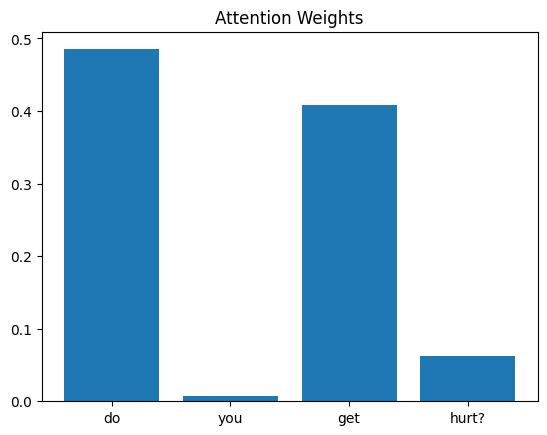

In [16]:
question = df["question"][0]
words = question.split()

with torch.no_grad():
    prediction, weights = model(X[:1])

plt.bar(words, weights[0, :len(words)].tolist())
plt.title("Attention Weights")
plt.show()

## Tasks:


Task 1 — Understand Attention Weights
Easy

Modify Step 6 to visualize the attention weights for three different questions from the dataset instead of only the first question.

Instructions:
- Select three questions from the dataset.
- Generate an attention bar chart for each question.
- Identify the word receiving the highest attention weight in each question.

Question: Do the words with the highest attention weights appear important for understanding the question? Explain your observations.

In [1]:
# Helper: get words, attention weights, and predicted answer
def get_attention(q):
    seq = tokenizer.texts_to_sequences([q])[0]
    words = [tokenizer.index_word[i] for i in seq]
    x = pad_sequences([seq], maxlen=X.shape[1], padding="post")
    x = torch.tensor(x, dtype=torch.long)
    with torch.no_grad():
        pred, w = model(x)
    return words, w[0, :len(words)].tolist(), pred.argmax(1).item()


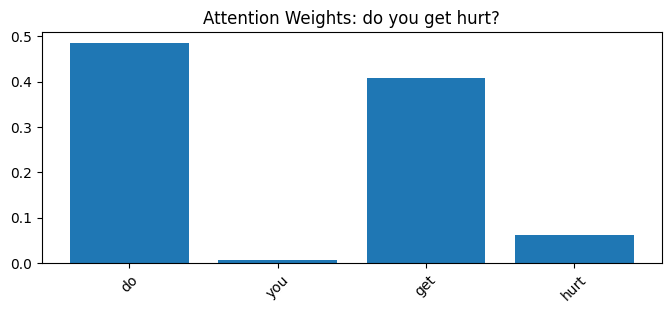

Highest attention word: do
Predicted: 0 | True: 0


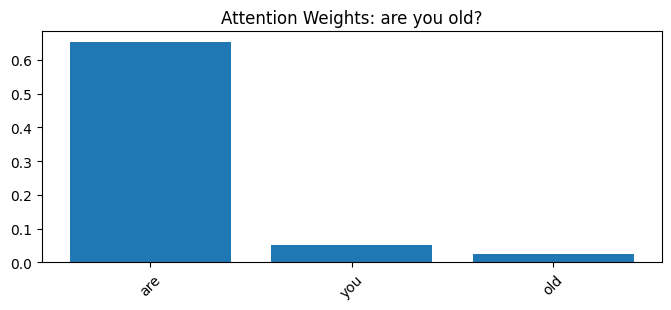

Highest attention word: are
Predicted: 3 | True: 1


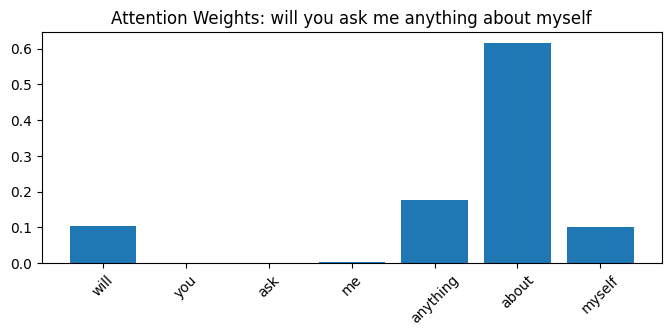

Highest attention word: about
Predicted: 2 | True: 2


In [17]:
# Three questions from three different answer groups
idx = df.drop_duplicates("answer_id").index[:3]

for i in idx:
    q = df["question"][i]
    words, w, pred = get_attention(q)
    plt.figure(figsize=(8, 3))
    plt.bar(range(len(words)), w)
    plt.xticks(range(len(words)), words, rotation=45)
    plt.title("Attention Weights: " + q)
    plt.show()
    print("Highest attention word:", words[w.index(max(w))])
    print("Predicted:", pred, "| True:", y[i].item())


The highest-attention words were "do" in "do you get hurt?", "are" in "are you old?", and "about" in "will you ask me anything about myself". These are mostly function or question-starting words rather than the content words that carry the meaning (such as "hurt" or "old"), so the highest weights do not always match what a human would consider important. However, the weights are not random: the word "you" received almost no attention in all three questions, probably because it appears in most questions and does not help the model separate the answers. Words like "do", "are" and "about" may act as cues for the question pattern. The model also predicted the wrong answer for "are you old?" (predicted 3, true 1), so attention shows what the model relied on, not necessarily what is semantically important.

Task 2 — Compare Attention for Similar Questions
Medium

Select two questions from the dataset that have similar meanings but different wording.

Instructions:
- Pass both questions through the trained model.
- Visualize their attention weights.
- Compare the words receiving the highest attention weights.

Question: Does the model focus on similar or different words when processing questions with similar meanings? What does this suggest about how attention works?

In [18]:
# Same helper as Task 1 (kept here so the cell runs alone)
def get_attention(q):
    seq = tokenizer.texts_to_sequences([q])[0]
    words = [tokenizer.index_word[i] for i in seq]
    x = pad_sequences([seq], maxlen=X.shape[1], padding="post")
    x = torch.tensor(x, dtype=torch.long)
    with torch.no_grad():
        pred, w = model(x)
    return words, w[0, :len(words)].tolist(), pred.argmax(1).item()


Q: are you old? | top word: are | predicted: 3
Q: what's your birthday? | top word: what's | predicted: 3


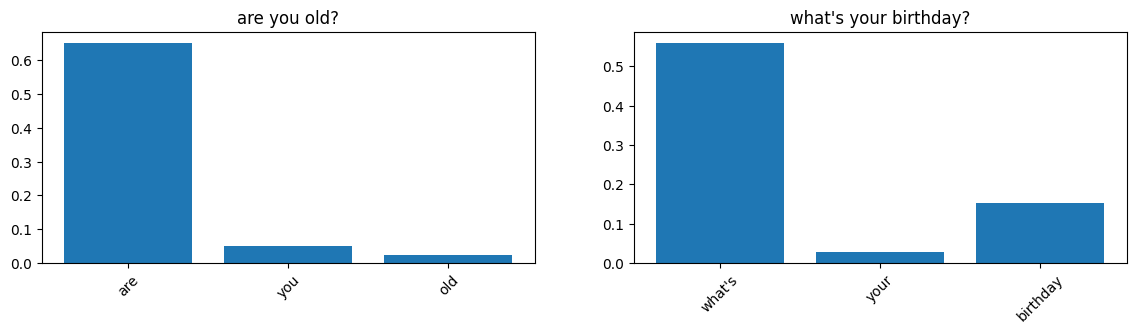

In [19]:
# Same answer_id, lowest word overlap = similar meaning, different wording
best = None
for aid, g in df.groupby("answer_id"):
    qs = g["question"].tolist()
    for a in range(len(qs)):
        for b in range(a + 1, len(qs)):
            s1, s2 = set(qs[a].split()), set(qs[b].split())
            j = len(s1 & s2) / len(s1 | s2)
            if best is None or j < best[0]:
                best = (j, qs[a], qs[b])

pair = [best[1], best[2]]
fig, axes = plt.subplots(1, 2, figsize=(14, 3))
tops = []
for ax, q in zip(axes, pair):
    words, w, pred = get_attention(q)
    ax.bar(range(len(words)), w)
    ax.set_xticks(range(len(words)))
    ax.set_xticklabels(words, rotation=45)
    ax.set_title(q)
    tops.append(words[w.index(max(w))])
    print("Q:", q, "| top word:", tops[-1], "| predicted:", pred)
plt.show()


The two questions, "are you old?" and "what's your birthday?", ask about the same topic (age) but share no words. The model focused on different words: "are" in the first question (about 0.65) and "what's" in the second (about 0.55), while the key words "old" and "birthday" received low weights. The model predicted the same answer (3) for both, although the true answer for both is 1, so the model is not fully trained. This suggests that attention does not detect meaning directly. It assigns weights to the words that were most useful for the model's learned prediction, so similar meanings with different wording can lead to attention on different words, often the question-starting words.